In [1]:
import sys 
import os
sys.path.append(r'/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/gaussfiltax')
import argparse
import jax.numpy as jnp
import jax.random as jr
from jax import vmap
import time
from flax import nnx
import matplotlib.pyplot as plt
import tensorflow_probability.substrates.jax.distributions as tfd # type: ignore
from util.misc import get_exp_dir, get_exp_data, get_data_for
import pprint

exp_root = '/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/exps'
fig_dir = '/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/figures'
tab_dir = '/Users/kostastsampourakis/Desktop/code/Python/projects/gaussfiltax/tables'

## View experiment

### Read data

In [2]:
ncomps = 100
M, N, L = 100, 5, 5
num_prt = 100
ac1 = 'prop'
r1 = 0.95
ac2 = 'prop'
r2 = 0.95

sim_args = {'ssm' : 'covinfl',
            'state_dim' : 1,
            'emission_dim' : 1,
            'num_timesteps' : 100,
            'a' : 10.0,
            'b' : 0.01
        }

args_lgsf = {'n_comps' : ncomps,
            'n_iters' : 1
        }

args_ugsf = {'n_comps' : ncomps,
            'n_iters' : 1,
            'alpha' : 1.0,
            'beta' : 0.0,
            'kappa' : 0.0
        }

args_lagsf = {'M' : M,
            'N' : N,
            'L' : L,
            'ac1' : ac1,
            'r1' : r1,
            'ac2' : ac2,
            'r2' : r2,
            'n_iters' : 1
        }

args_uagsf = {'M' : M,
            'N' : N,
            'L' : L,
            'ac1' : ac1,
            'r1' : r1,
            'ac2' : ac2,
            'r2' : r2,
            'n_iters' : 1
        }

args_bpf = {'M' : num_prt,
            'ess' : 0.5
        }

args_apf = {'M' : num_prt,
            'ess' : 0.5
        }

inf_args = {'lgsf' : args_lgsf,
            'ugsf' : args_ugsf,
            'lagsf' : args_lagsf,
            'uagsf' : args_uagsf,
            'bpf' : args_bpf,
            'apf' : args_apf
        }

out = {}

for alg in inf_args.keys():

        try:

            data = get_data_for(alg, sim_args, inf_args[alg], 1, 20)
            out[alg] = data

        except Exception as e:
              
                print(f"Error processing algorithm {alg}: {e}")
                out[alg] = None
    

In [3]:
def plot_errors(alg, trial):

    metrics = ['lpe', 'bs', 'me', 'mse']
    fig, ax = plt.subplots(1, len(metrics), figsize=(16, 3))

    for j, metric in enumerate(metrics):

        err_traj = out[alg][metric][trial][1]
        ax[j].plot(err_traj, label=f'{metric.upper()} over time', linewidth=2)
        ax[j].set_title(f'{alg} - {metric.upper()} (Trial {trial})')
        ax[j].set_xlabel('Time Steps')
        ax[j].set_ylabel('Error')
        ax[j].legend()

    plt.tight_layout()

In [4]:
error_trials = {}

for alg in out.keys():

    if out[alg] is not None:

        di = {}

        for err_type in ['lpe', 'bs', 'me', 'mse']:
    
           di[err_type]  = jnp.array([err[0] for err in out[alg][err_type]])

        error_trials[alg] = di

        try:

            lpe_m, lpe_std = out[alg]['averaged_errors']['LPE']
            bs_m, bs_std = out[alg]['averaged_errors']['bias']
            me_m, me_std = out[alg]['averaged_errors']['ME']
            mse_m, mse_std = out[alg]['averaged_errors']['MSE']

        except Exception as e:

            print(f"Error extracting averaged errors for algorithm {alg}: {e}")
            lpe_m, lpe_std, bs_m, bs_std, me_m, me_std, mse_m, mse_std = None, None, None, None, None, None, None, None

### Error table

In [5]:
import numpy as np

algs = list(out.keys())
error_keys = ['lpe', 'mse', 'bs', 'me']
summary = []

for alg in algs:

    try:

        # stack all trials (assuming error_trials[alg][key] is a list/array over trials)
        means = {}

        for key in error_keys:

            arr = np.array(error_trials[alg][key])  # shape: (n_trials, ...) or flat
            means[key] = np.nanmean(arr)  # ignore NaNs if any

        summary.append((alg, means))

    except KeyError:

        # in case alg missing or some key missing
        summary.append((alg, {key: np.nan for key in error_keys}))

# print table
print("Average Error Summary\n")
print(f"{'Algorithm':<15} {'LPE':<12} {'MSE':<12} {'BS':<12} {'ME':<12}")

for alg, means in summary:

    print(f"{alg:<15} "
          f"{means['lpe']:<12.4e} "
          f"{means['mse']:<12.4e} "
          f"{means['bs']:<12.4e} "
          f"{means['me']:<12.4e}")

Average Error Summary

Algorithm       LPE          MSE          BS           ME          
lgsf            5.2424e+00   3.1515e+02   1.0938e+01   1.9607e+00  
ugsf            1.6661e+00   1.6237e+00   1.0288e+00   5.3786e-01  
lagsf           3.2313e+00   3.2875e+00   1.3725e+00   1.2566e-01  
uagsf           1.6286e+00   1.5189e+00   9.8821e-01   2.7892e-01  
bpf             1.8953e+00   1.5000e+00   9.8712e-01   3.6525e-02  
apf             2.0037e+00   1.6240e+00   1.0384e+00   3.9113e-02  


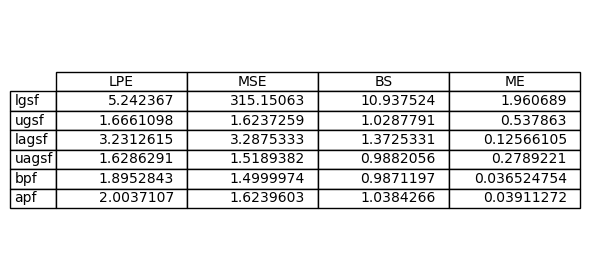

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# convert summary to DataFrame
df = pd.DataFrame({
    'Algorithm': [alg for alg, _ in summary],
    'LPE': [m['lpe'] for _, m in summary],
    'MSE': [m['mse'] for _, m in summary],
    'BS':  [m['bs']  for _, m in summary],
    'ME':  [m['me']  for _, m in summary],
})
df.set_index('Algorithm', inplace=True)


tab_name = f'average_error_summary_b_{sim_args['b']}.csv'
df.to_csv(tab_dir + f'/{tab_name}', index=True)
# plot table
fig, ax = plt.subplots(figsize=(6, 0.5 + 0.4*len(df)))
ax.axis('off')
tbl = ax.table(cellText=df.values,
               colLabels=df.columns,
               rowLabels=df.index,
               loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
fig.tight_layout()

fig.savefig(fig_dir + '/average_error_summary.png')

### GSF

In [7]:
print('LGSF')
pprint.pprint(error_trials['lgsf'])
print('-'*88)
print('UGSF')
pprint.pprint(error_trials['ugsf'])

LGSF
{'bs': Array([12.31523  , 11.918119 , 12.939345 , 11.103494 , 12.684777 ,
       10.751872 , 12.248747 ,  6.7283206,  9.411938 , 13.212004 ,
        9.486914 , 12.936421 , 11.172589 ,  9.680377 ,  8.606963 ,
       11.797691 , 10.812441 ,  9.87607  , 10.039115 , 11.028048 ],      dtype=float32),
 'lpe': Array([5.3247986, 5.2684584, 5.2878633, 5.23407  , 5.2896404, 5.2238016,
       5.3222504, 5.1492677, 5.2518425, 5.2196884, 5.2555594, 5.3487744,
       5.262191 , 5.209637 , 5.143754 , 5.2961936, 5.168573 , 5.1737943,
       5.2012615, 5.215914 ], dtype=float32),
 'me': Array([2.2909505, 1.7323613, 1.7407581, 2.0793302, 1.8579985, 2.495041 ,
       2.2383335, 1.4339   , 1.9672159, 1.8538412, 1.8646768, 2.2482972,
       2.3448858, 1.4869256, 1.7322644, 2.2414613, 1.9453927, 1.915299 ,
       1.9211811, 1.8236668], dtype=float32),
 'mse': Array([388.94702 , 312.31534 , 388.99164 , 306.4516  , 341.59796 ,
       341.0606  , 452.58835 , 103.980316, 175.70142 , 405.73938 ,
       219.

In [8]:
def plot_gsf_trajectory(alg, trial):

    means = out[alg]['results'][trial]['means']#.mean(axis=0)
    covs = out[alg]['results'][trial]['covariances']
    states = out[alg]['gt'][trial][0]
    diag_covs = jnp.einsum('ijkk->ijk', covs)


    T = means.shape[1]
    time = jnp.arange(T)

    n_comp = means.shape[0]
    n_dim = means.shape[2]

    colors = plt.cm.viridis(jnp.linspace(0, 1, n_comp))
    labels = [f'comp {k}' for k in range(n_comp)]

    for k in range(n_comp):
        
        m = means[k, :, 0]
        var = diag_covs[k, :, 0]
        std = jnp.sqrt(var)

        plt.plot(time, m, color=colors[k])
        plt.fill_between(time,
                        m - 2 * std,
                        m + 2 * std,
                        alpha = 0.2,
                        color = colors[k])

    plt.plot(states[:, 0], label='Ground Truth', linewidth=2)
    plt.legend()
    plt.xlabel('time')
    plt.ylabel('value')
    plt.tight_layout()

def plot_gsf_slices(alg, trial, ts):

    means = out[alg]['results'][trial]['means']
    covs = out[alg]['results'][trial]['covariances']
    states = out[alg]['gt'][trial][0]
    diag_covs = jnp.einsum('ijkk->ijk', covs)
    n_comp = means.shape[0]
    n_sigma = 4

    num_plots = len(ts)

    fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 4))

    for i, t in enumerate(ts):

        plt.sca(axes[i]) if num_plots > 1 else plt.sca(axes)

        comp_means = means[:, t, 0]
        comp_vars = diag_covs[:, t, 0]
        comp_std = jnp.sqrt(comp_vars + 1e-12)
        comp_std = jnp.clip(comp_std, 1e-3, None)

        lo = jnp.min(comp_means - n_sigma * comp_std)
        hi = jnp.max(comp_means + n_sigma * comp_std)

        # include ground truth and add a small padding
        gt = states[t, 0]
        lo = jnp.minimum(lo, gt)
        hi = jnp.maximum(hi, gt)
        pad = 0.1 * (hi - lo + 1e-6)
        lo = float(lo - pad); hi = float(hi + pad)

        if hi - lo < 1e-3:

            lo -= 0.5; hi += 0.5

        x_vals = jnp.linspace(lo, hi, 500)

        for k in range(n_comp):

            m = float(comp_means[k])
            std = float(comp_std[k])
            pdf = (1.0 / (std * jnp.sqrt(2 * jnp.pi))) * jnp.exp(-0.5 * ((x_vals - m) / std) ** 2)
            plt.plot(x_vals, pdf, alpha=0.8)

        plt.plot(float(gt), 0, marker='v', color='k', label='GT')
        plt.title(f'Posterior Marginal PDF at t={t}')
        plt.xlabel('Value')
        plt.ylabel('Density')
        plt.tight_layout()


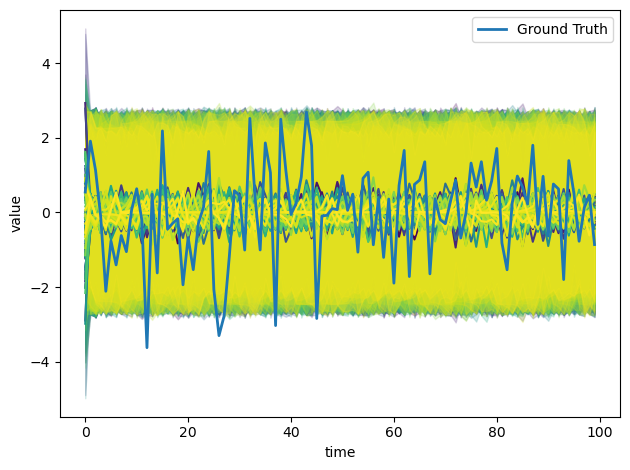

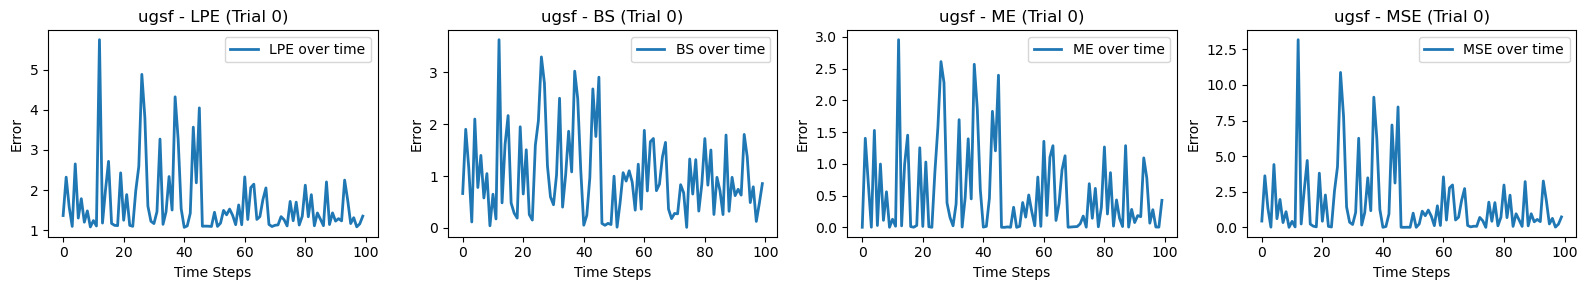

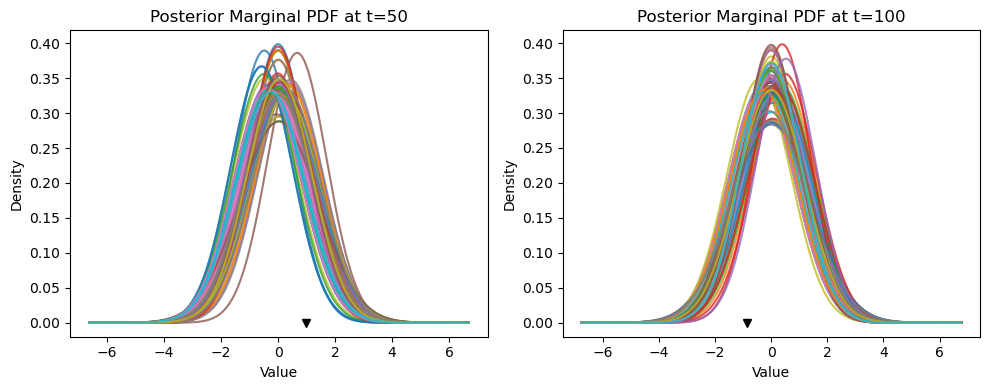

In [19]:
alg = 'ugsf'
trial = 0
plot_gsf_trajectory(alg, trial)
plt.show()
plot_errors(alg, trial)
plt.show()
plot_gsf_slices(alg, trial, [50, 100])


### AGSF

In [10]:
def plot_agsf_trajectory(alg, trial):

    means = out[alg]['results'][trial]['means'] 
    covs = out[alg]['results'][trial]['covariances']
    states = out[alg]['gt'][trial][0]
    diag_covs = jnp.einsum('ijkk->ijk', covs)

    T = means.shape[1]
    time = jnp.arange(T)

    n_comp = means.shape[0]
    n_dim = means.shape[2]

    colors = plt.cm.viridis(jnp.linspace(0, 1, n_comp))
    labels = [f'comp {k}' for k in range(n_comp)]

    for k in range(n_comp):
        
        m = means[k, :, 0]
        var = diag_covs[k, :, 0]
        std = jnp.sqrt(var)

        plt.plot(time, m, color=colors[k])
        plt.fill_between(time,
                        m - 2 * std,
                        m + 2 * std,
                        alpha = 0.2,
                        color = colors[k])
    plt.plot(states[:], label='Ground Truth', linewidth=2)
    plt.xlabel('time')
    plt.ylabel('value')

    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_agsf_slices(alg, trial, ts):

    means = out[alg]['results'][trial]['means']
    covs = out[alg]['results'][trial]['covariances']
    states = out[alg]['gt'][trial][0]
    n_comp = means.shape[0]
    n_sigma = 4
    diag_covs = jnp.einsum('ijkk->ijk', covs)


    num_plots = len(ts)
    fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 4))

    for i, t in enumerate(ts):

        plt.sca(axes[i]) if num_plots > 1 else plt.sca(axes)            

        comp_means = means[:, t]
        comp_vars = diag_covs[:, t]
        comp_std = jnp.sqrt(comp_vars + 1e-12)
        comp_std = jnp.clip(comp_std, 1e-3, None)

        lo = jnp.min(comp_means - n_sigma * comp_std)
        hi = jnp.max(comp_means + n_sigma * comp_std)

        # include ground truth and add a small padding
        gt = states[t]
        lo = jnp.minimum(lo, gt)
        hi = jnp.maximum(hi, gt)
        pad = 0.1 * (hi - lo + 1e-6)
        lo = lo - pad; hi = hi + pad

        if hi - lo < 1e-3:

            lo -= 0.5; hi += 0.5

        x_vals = jnp.linspace(lo, hi, 500)

        for k in range(n_comp):

            m = comp_means[k]
            std = comp_std[k]
            pdf = (1.0 / (std * jnp.sqrt(2 * jnp.pi))) * jnp.exp(-0.5 * ((x_vals - m) / std) ** 2)
            plt.plot(x_vals, pdf, alpha=0.8)

        plt.plot(gt, 0, marker='v', color='k', label='GT')
        plt.title(f'Posterior Marginal PDF at t={t}')
        plt.xlabel('Value')
        plt.ylabel('Density')
        plt.legend(fontsize=8)

        plt.tight_layout()

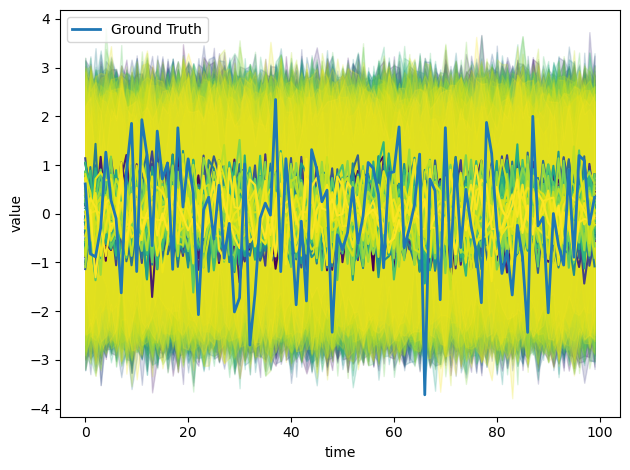

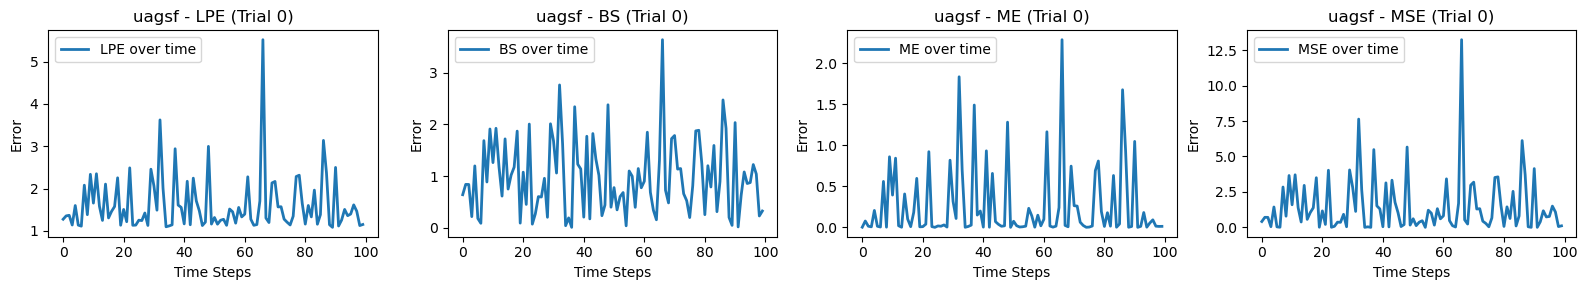

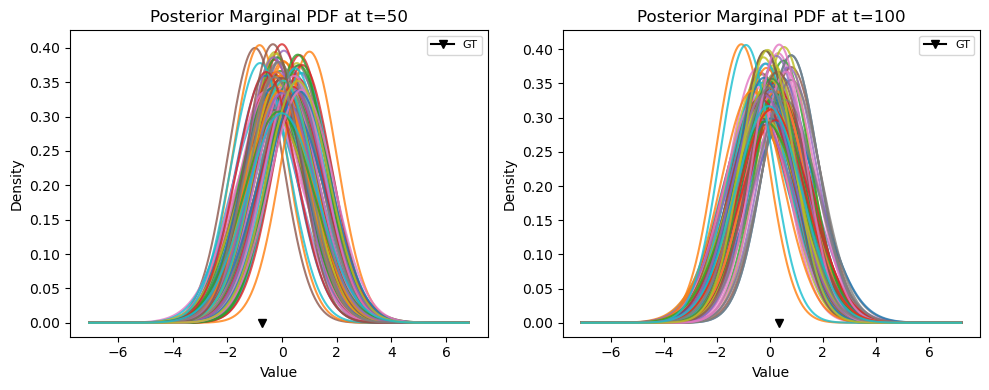

In [20]:
alg = 'uagsf'
trial = 0
plot_agsf_trajectory(alg, trial)
plot_errors(alg, trial)
plot_agsf_slices(alg, trial, [50, 100])

### BPF

In [12]:
def plot_bpf_trajectory(alg, trial):

    states = out[alg]['gt'][trial][0]
    particles = out[alg]['results'][trial][0]['particles']
    means = particles.mean(axis=0)

    plt.plot(states[:], label='Ground Truth', linewidth=2)
    plt.plot(means[:], linestyle='dotted', label='Particle mean')

    for p in range(min(20, particles.shape[0])):  

        plt.plot(particles[p, :], color='gray', alpha=0.1)

    plt.legend(fontsize=8)

    plt.tight_layout()

def plot_bpf_slices(alg, trial, ts):

    states = out[alg]['gt'][trial][0]
    particles = out[alg]['results'][trial][0]['particles']
    means = particles.mean(axis=0)

    T = particles.shape[1]

    n_sigma = 4
    n_pts = 500
    n_particles = particles.shape[0]
    d = 0

    num_plots = len(ts)
    fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 4))

    for i, t in enumerate(ts):

        plt.sca(axes[i]) if num_plots > 1 else plt.sca(axes)    

        samples = jnp.asarray(particles[:, t, d]).astype(jnp.float32)  # shape (M,)

        # Silverman bandwidth (with safeguards)
        std = jnp.std(samples)
        std = jnp.where(std == 0.0, 1e-3, std)
        h = 1.06 * std * (samples.size ** (-1/5))
        h = jnp.maximum(h, 1e-3)

        # adaptive x range around mixture components and ground truth
        comp_mean = jnp.mean(samples)
        lo = float(jnp.min(samples - n_sigma * std))
        hi = float(jnp.max(samples + n_sigma * std))
        gt = float(states[t, d])  # ground truth at time t
        lo = min(lo, gt)
        hi = max(hi, gt)
        pad = 0.1 * (hi - lo + 1e-12)
        lo -= pad; hi += pad

        if hi - lo < 1e-3:

            lo -= 0.5; hi += 0.5

        x_grid = jnp.linspace(lo, hi, n_pts)

        # vectorized Gaussian kernel density estimate
        diffs = (x_grid[:, None] - samples[None, :]) / h
        kernel_vals = jnp.exp(-0.5 * (diffs ** 2)) / jnp.sqrt(2 * jnp.pi)
        pdf = jnp.mean(kernel_vals, axis=1) / h

        ax = axes[i]
        ax.plot(x_grid, pdf, lw=1.5, label=f'KDE (t={t})')
        # show ground truth as vertical marker
        ax.axvline(gt, color='k', linestyle='--', label='GT')
        # optional: rug plot for particles
        y_rug = 0.02 * jnp.max(pdf)
        ax.plot(samples, jnp.full_like(samples, y_rug), '|', color='C1', alpha=0.6, label='particles' if d == 0 else "")

        ax.set_title(f"Dim {d} posterior (t={t})")
        ax.set_xlabel("value")
        ax.set_ylabel("density")
        if d == 0:
            ax.legend(fontsize=8)

        plt.tight_layout()

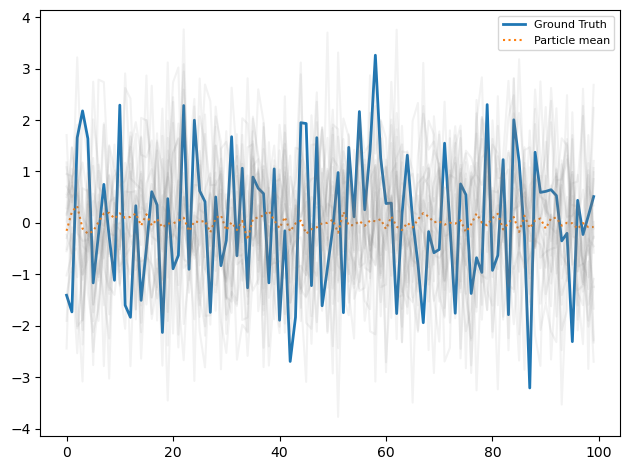

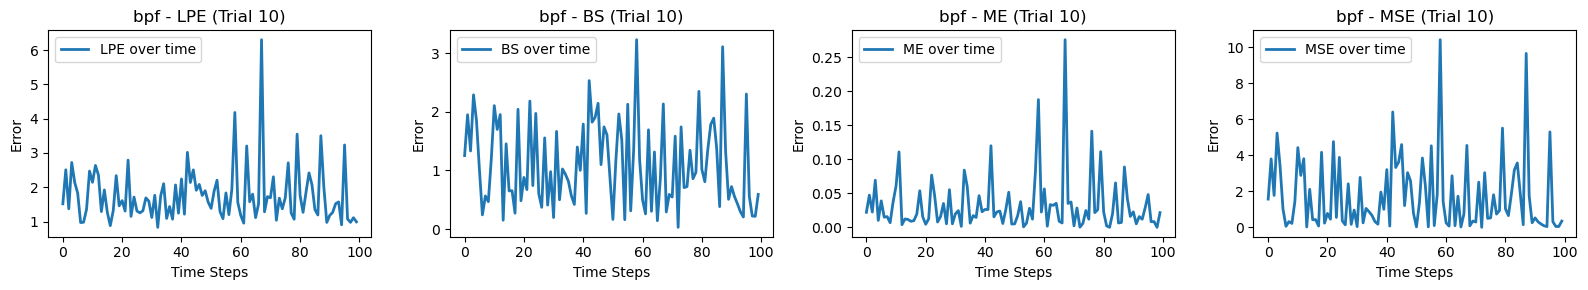

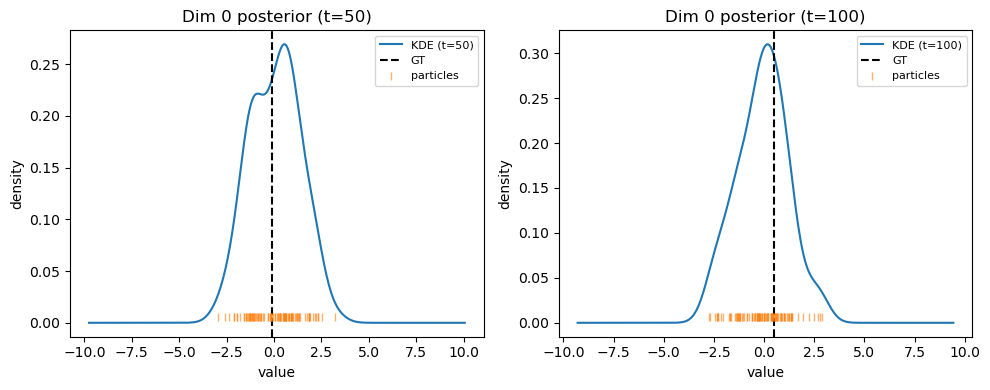

In [13]:
alg = 'bpf'
trial = 10
plot_bpf_trajectory(alg, trial)
plot_errors(alg, trial)
plot_bpf_slices(alg, trial, [50, 100])

## ERROR PLOTS

### Given Trial

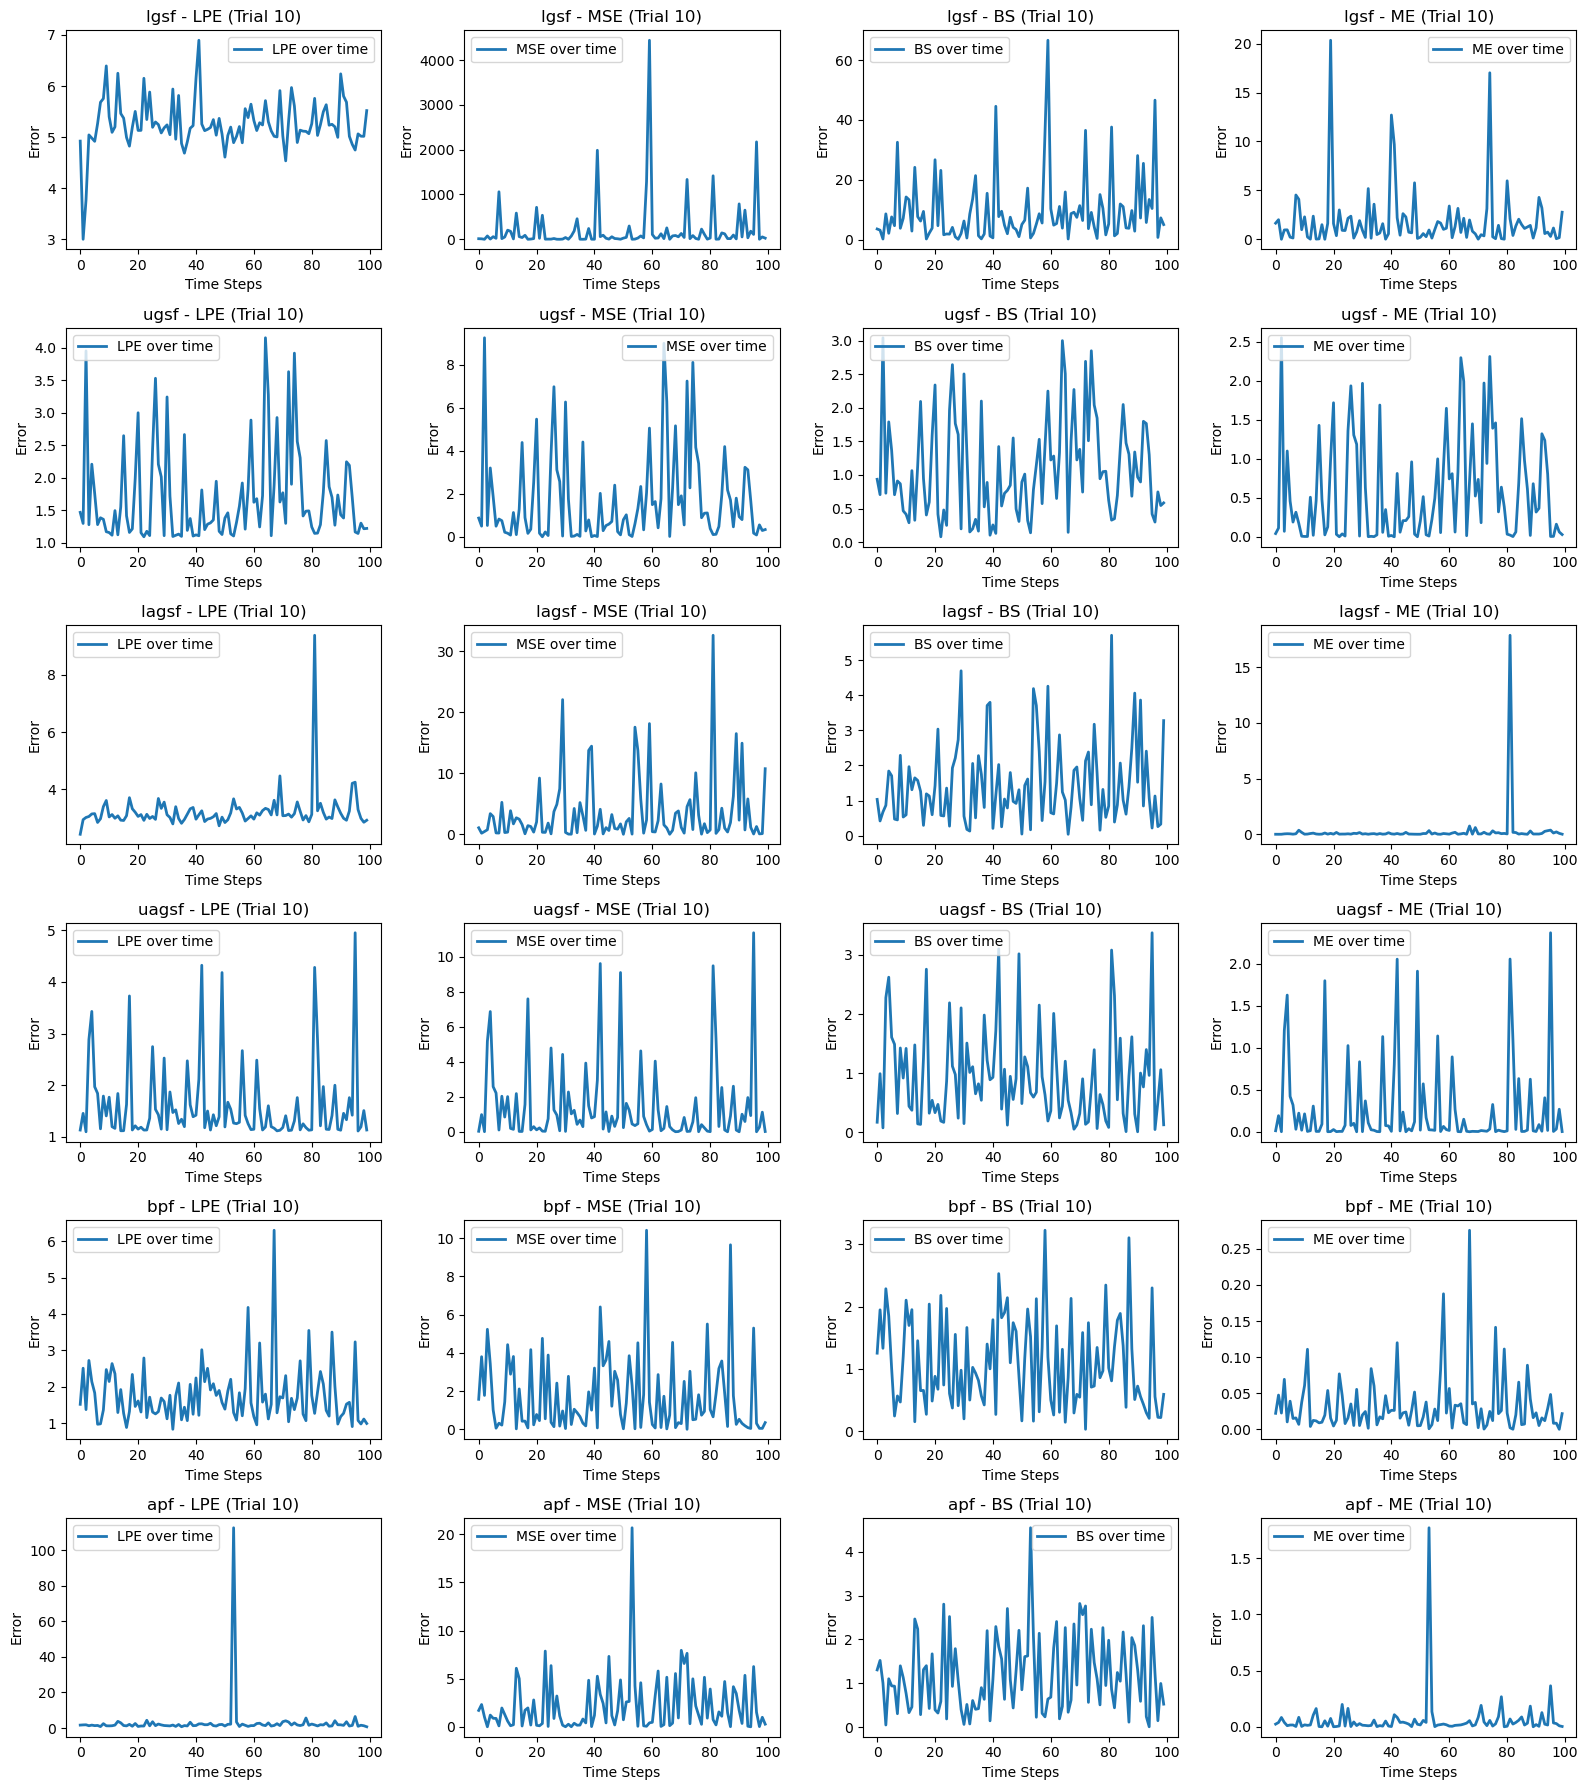

Error Summary for Trial 10:

Algorithm  LPE          MSE          BS           ME          
lgsf       5.2556e+00   2.1909e+02   9.4869e+00   1.8647e+00  
ugsf       1.6938e+00   1.7137e+00   1.0835e+00   5.7634e-01  
lagsf      3.2227e+00   3.5160e+00   1.4728e+00   2.6151e-01  
uagsf      1.6098e+00   1.4621e+00   9.2298e-01   2.7151e-01  
bpf        1.7579e+00   1.7349e+00   1.1008e+00   3.2217e-02  
apf        3.0362e+00   2.1790e+00   1.1941e+00   6.0256e-02  


In [14]:
## Plot errors for trial

algs = list(out.keys())
metrics = ['lpe', 'mse', 'bs', 'me']
fig, axes = plt.subplots(len(algs), len(metrics), figsize=(16, 3 * len(algs)), squeeze=False)
for i, alg in enumerate(algs):
    for j, metric in enumerate(metrics):
        ax = axes[i, j]
        err_traj = out[alg][metric][trial][1]
        ax.plot(err_traj, label=f'{metric.upper()} over time', linewidth=2)
        ax.set_title(f'{alg} - {metric.upper()} (Trial {trial})')
        ax.set_xlabel('Time Steps')
        ax.set_ylabel('Error')
        ax.legend()

plt.tight_layout()
plt.show()

print(f"Error Summary for Trial {trial}:\n")
print(f"{'Algorithm':<10} {'LPE':<12} {'MSE':<12} {'BS':<12} {'ME':<12}")

for alg in algs:
    try:
        (lpe, _), (mse, _), (bs, _), (me, _) = (
            out[alg]['lpe'][trial],
            out[alg]['mse'][trial],
            out[alg]['bs'][trial],
            out[alg]['me'][trial],
        )
        print(
            f"{alg:<10} "
            f"{lpe:<12.4e} "
            f"{mse:<12.4e} "
            f"{bs:<12.4e} "
            f"{me:<12.4e}"
        )
    except Exception:
        print(f"{alg:<10} {'Error':<12} {'Error':<12} {'Error':<12} {'Error':<12}")

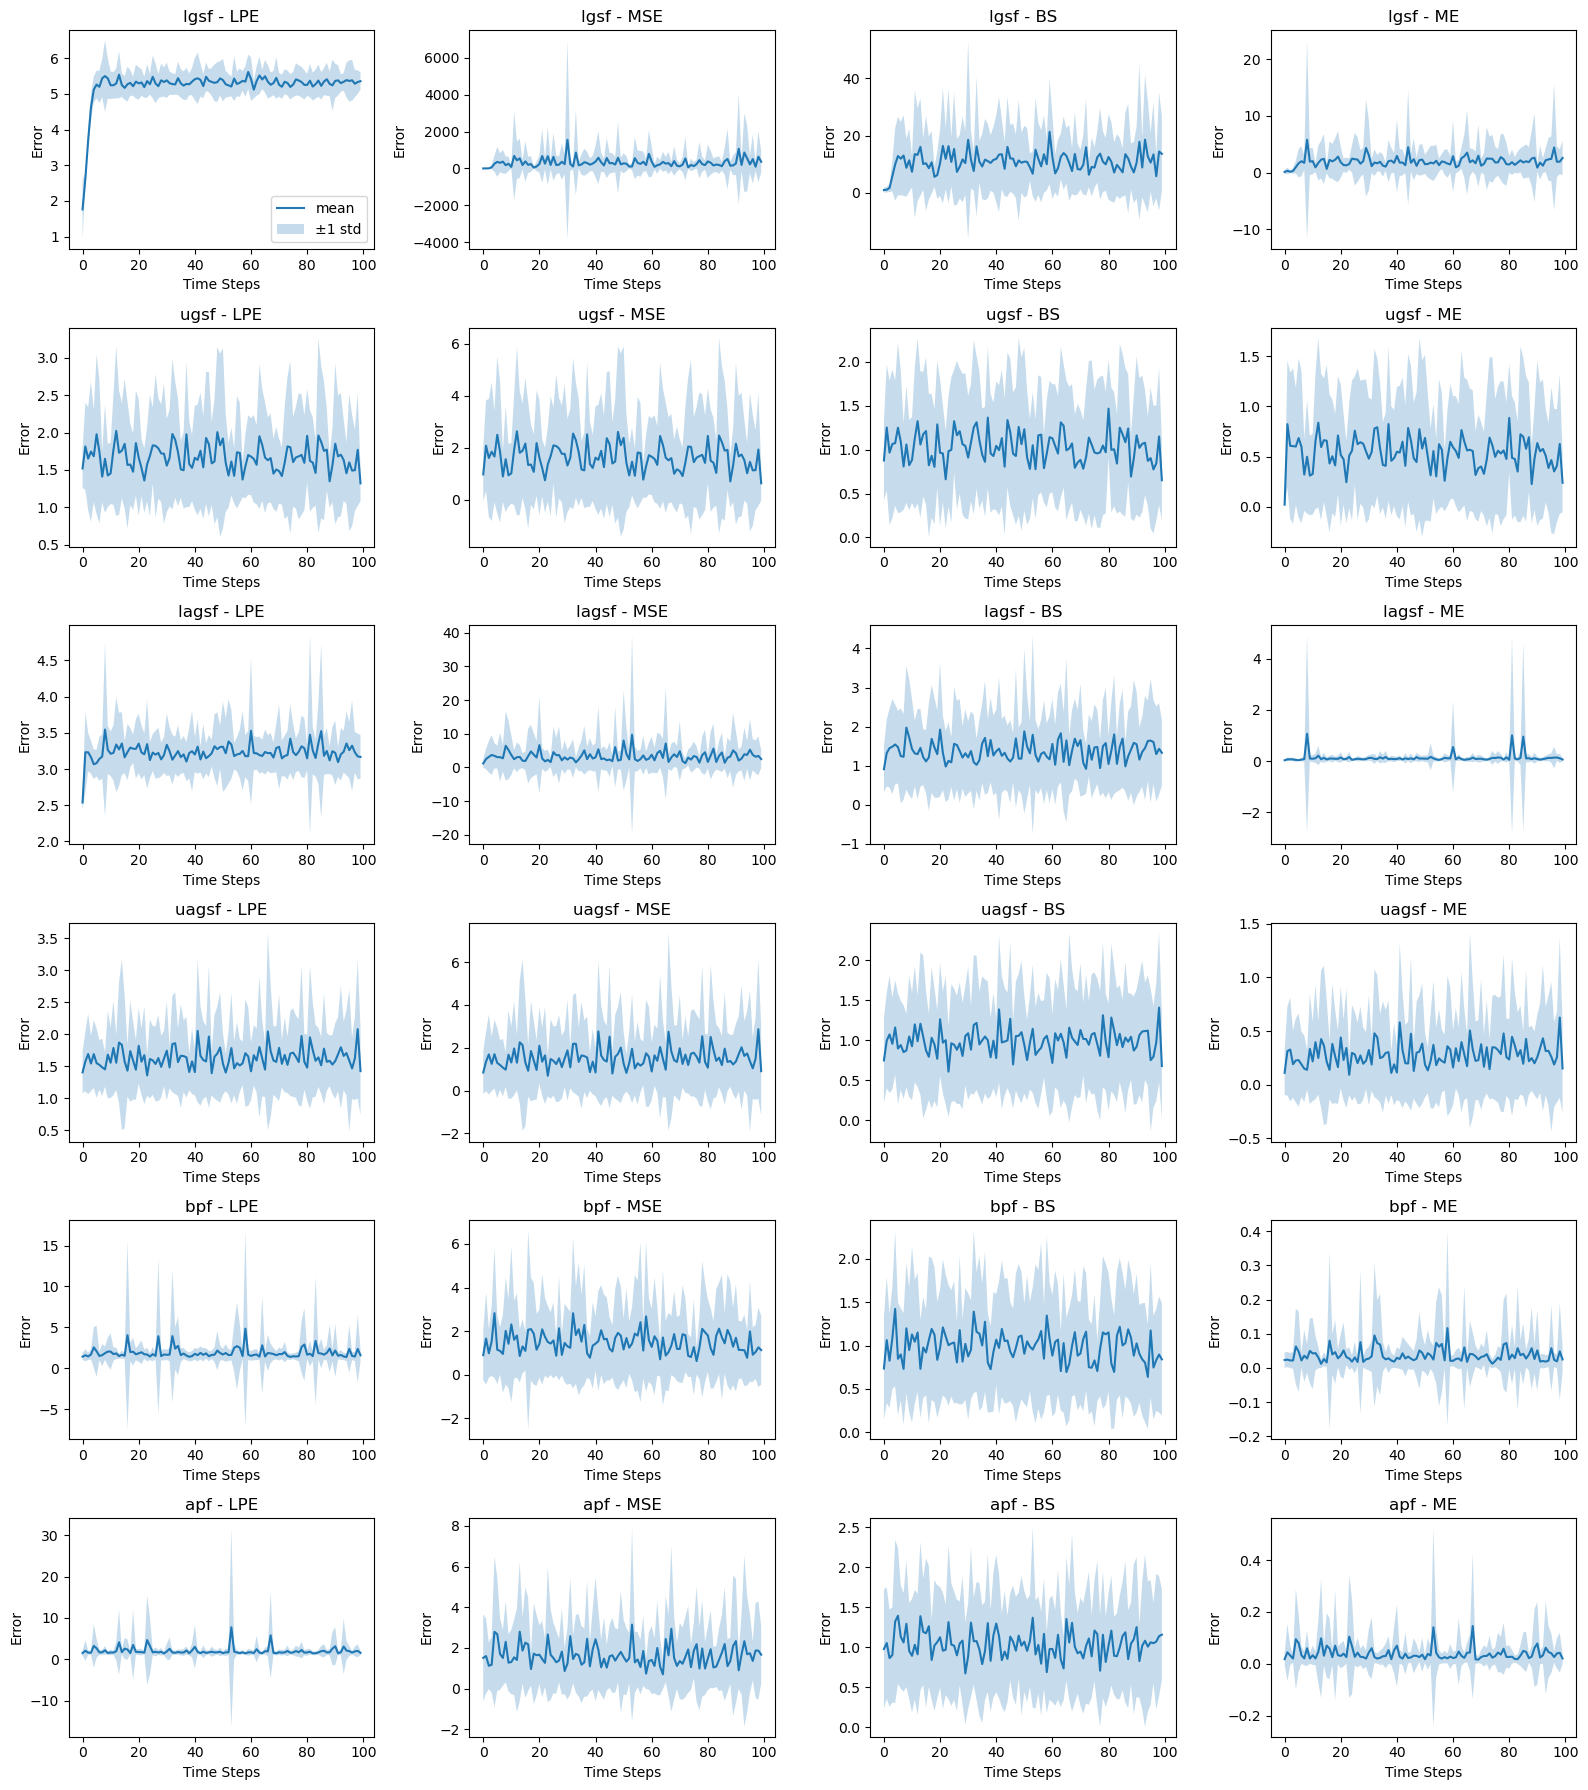

In [15]:
import numpy as np
algs = list(out.keys())
metrics = ['lpe', 'mse', 'bs', 'me']

fig, axes = plt.subplots(len(algs), len(metrics), figsize=(16, 3 * len(algs)), squeeze=False)

for i, alg in enumerate(algs):

    for j, met in enumerate(metrics):

        try:

            trials = out[alg].get(met, [])
            valid_series = []

        except Exception as e:

            print(f"Error retrieving trials for {alg} - {met}: {e}")
            trials = []
            valid_series = []

        for entry in trials:

            try:

                _, ts = entry
                ts = np.asarray(ts)
                valid_series.append(ts)

            except Exception:

                continue

        ax = axes[i, j]
        ax.set_title(f"{alg} - {met.upper()}")
        ax.set_xlabel("Time Steps")
        ax.set_ylabel("Error")

        if len(valid_series) == 0:

            ax.text(0.5, 0.5, "No data", ha="center", va="center")

            continue

        arr = np.vstack(valid_series)  # shape: (n_trials, T)
        mean = arr.mean(axis=0)
        std = arr.std(axis=0)
        x = np.arange(mean.size)

        ax.plot(x, mean, lw=1.5, label='mean')
        ax.fill_between(x, mean - std, mean + std, alpha=0.25, label='±1 std')
        if i == 0 and j == 0:
            ax.legend()

plt.tight_layout()
plt.show()

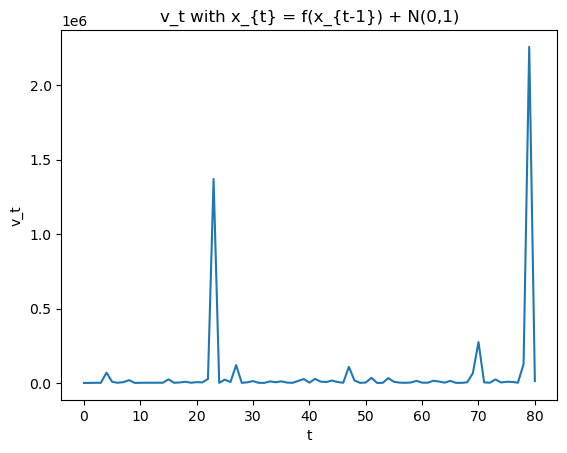

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# example functions
def f(x): return np.sin(10 * x)
def g(x): return 0.01 * x**2

def df(x): return 10 * np.cos(10 * x)
def dg(x): return 0.02 * x

def update_v(v, F, G):

    return (F*F * v + 1) / (G*G * F*F * v + G*G + 1)

def run(v0, x0, T):

    v = v0
    x = x0
    vs, xs = [v], [x]

    for _ in range(T):

        F = df(x)
        G = dg(x)
        v = update_v(v, F, G)
        x = f(x) + np.random.randn()
        vs.append(v)
        xs.append(x)

    return np.array(xs), np.array(vs)

v0 = 0.5
x0 = 0.0
T = 80

xs, vs = run(v0, x0, T)

plt.figure()
plt.plot(vs)
plt.title("v_t with x_{t} = f(x_{t-1}) + N(0,1)")
plt.xlabel("t")
plt.ylabel("v_t")
plt.show()